# 06 · Making turbulence write a letter

Everything comes together :) We start from **uniform gas** with a **random turbulent velocity field** and ask:

> *What initial velocity field makes the gas, after evolving freely under the Euler equations for a time $T$, pile up
> into the shape of a letter?*

There is no forcing and no density structure in the initial condition: whatever shape appears at $t = T$ has to be
**assembled by the flow**, through compressions, shocks and swirls. We solve this as an optimisation problem over
$2 \times N^2$ numbers (two white-noise fields), with gradients obtained by differentiating through several hundred
diffhydro steps.

| ingredient | from notebook |
|---|---|
| finite volumes, CFL, shocks | 01, 03 |
| reverse-mode gradients through time, checkpointing, Adam, coarse-to-fine losses, whitened priors | 02 |
| HLLC + MUSCL + RK, validated against exact solutions | 03, 04 |
| `diffhydro`, `evolve_with_dt_schedule` | 04 |
| turbulent IC from white noise, compressive vs solenoidal flows, sensitivity and horizons | 05 |

**Runtime.** A GPU does this at $128^2$ in a few minutes. On a CPU the defaults drop to $48^2$ (still a
recognisable letter, ~15 minutes on a recent multi-core CPU). Change `N` and `ITERS` below to taste.

In [ ]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from scipy import ndimage

try:
    import diffhydro as dh
except ImportError:
    sys.path.insert(0, "../..")
    import diffhydro as dh
import tutorial_utils as tu

plt.rcParams.update({"figure.dpi": 100, "axes.grid": False, "image.interpolation": "nearest"})
ON_GPU = jax.default_backend() == "gpu"
print("JAX backend:", jax.default_backend())

LETTER = "D"
N = 128 if ON_GPU else 48          # grid cells per side
ITERS = 300 if ON_GPU else 120     # optimization steps

# physics of the forward model
GAMMA = 5 / 3      # adiabatic ideal gas
MACH = 1.0         # rms Mach number of the initial turbulence (for unit-variance white noise)
KCUT = 8.0         # IC power cut off above ~8 eddies per box side
T_END = 0.25       # evolution time in sound-crossing times of the box
CONTRAST = 2.0     # target: rho / <rho> - 1 = CONTRAST * (ink - <ink>)

JAX backend: gpu


## 1. The target

We rasterise the glyph with matplotlib (no image files needed): draw it large, crop to its bounding box, scale it to fill
70% of the box, and average down to $N\times N$ for anti-aliased edges. The result is an "ink" map in $[0, 1]$.
We also keep blurred copies for the coarse-to-fine schedule (notebook 02, section 5).

Note that for these sorts of "unphysical" reconstructions (i.e. for logos) thicker features are easier for the optimizer to learn in my experience.

ink covers 30% of the box


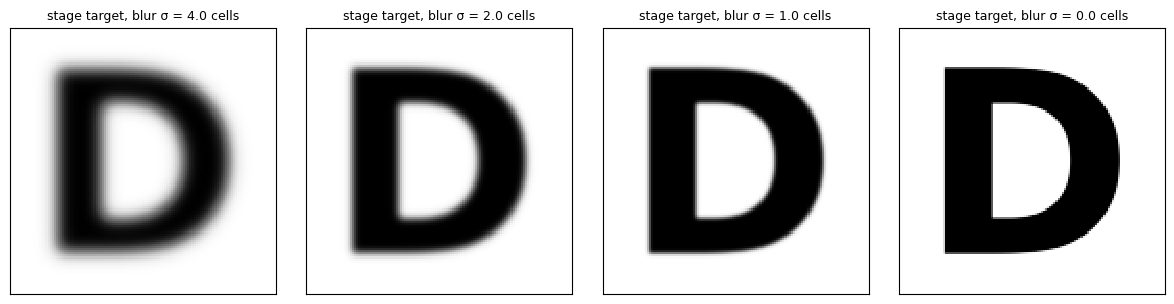

In [2]:
def render_letter(ch, n, fill=0.7, oversample=4):
    # rasterise a glyph -> ink in [0, 1] on an n x n grid indexed [x, y] with y up
    m = n * oversample
    fig = plt.figure(figsize=(1, 1), dpi=m)
    fig.text(0.5, 0.5, ch, ha="center", va="center", fontsize=0.8 * 72, fontweight="bold", family="DejaVu Sans")
    fig.canvas.draw()
    ink = 1.0 - np.asarray(fig.canvas.buffer_rgba())[..., 0] / 255.0
    plt.close(fig)
    rows, cols = np.nonzero(ink > 0.5)
    ink = ink[rows.min():rows.max() + 1, cols.min():cols.max() + 1]          # crop to the glyph
    ink = ndimage.zoom(ink, fill * m / max(ink.shape), order=1)              # longest side = fill * box
    canvas = np.zeros((m, m))
    r0, c0 = (m - ink.shape[0]) // 2, (m - ink.shape[1]) // 2
    canvas[r0:r0 + ink.shape[0], c0:c0 + ink.shape[1]] = ink
    ink = canvas.reshape(n, oversample, n, oversample).mean(axis=(1, 3))     # anti-aliased downsample
    return np.clip(ink[::-1].T, 0.0, 1.0)                                    # image rows -> [x, y]

ink = render_letter(LETTER, N)
BLURS = [4.0, 2.0, 1.0, 0.0]           # Gaussian blur of the residual (in cells, scaled to N=128), per stage
blur_px = [b * N / 128 for b in BLURS]

fig, axes = plt.subplots(1, len(BLURS), figsize=(3 * len(BLURS), 3))
for ax, b in zip(axes, blur_px):
    ax.imshow(ndimage.gaussian_filter(ink, b, mode="wrap").T, origin="lower", cmap="Greys", vmin=0, vmax=1)
    ax.set_title(f"stage target, blur σ = {b:.1f} cells", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
print(f"ink covers {100 * ink.mean():.0f}% of the box")

## 2. The forward model: white noise → turbulence → density at $T$

Key Elements

1. **IC**: `tu.make_turbulent_ic` from notebook 05 maps two white-noise fields $w = (w_\phi, w_\psi)$ to a velocity
   field (half compressive, half solenoidal, $P(k)\propto k^{-2}e^{-(k/k_\mathrm{cut})^2}$, rms Mach 1) on top of uniform
   density and pressure. It is linear in $w$, band-limited (the optimiser can't paint pixel-scale noise), and the
   prior $w\sim\mathcal N(0,1)$ keeps the flow at a "typical" turbulent amplitude.
2. **Evolution**: HLLC + MUSCL3 + RK2 on a periodic box, `evolve_with_dt_schedule` with a fixed $\Delta t$ so that
   every candidate IC is compared at exactly $t = T$. The step is chosen safely below the CFL limit for flows up to
   ~3× the rms Mach number.
3. **Observable**: the density field $\rho(\mathbf x, T)$. (Try out the same thing with temperature or some other derived observable!)

As a safety net we switch on diffhydro's *state repair* (density/pressure floors applied inside each step), which keeps
a wild intermediate IC from producing negative pressures and NaN gradients early in the optimization. This is somewhat heavy handed, but the simplest way to make sure the backpropogation is stable.

In [3]:
eq, sim = tu.make_hydro(N, N, gamma=GAMMA)
sim.enable_hydro_state_repair = True
sim.hydro_repair_rho_floor = 1e-3
sim.hydro_repair_pressure_floor = 1e-4 / GAMMA

ic = tu.make_turbulent_ic(N, mach=MACH, kcut=KCUT, pslope=-2.0, solenoidal_fraction=0.5, gamma=GAMMA)
dt = 0.3 / N / (1 + 3 * MACH)                  # CFL 0.3 for |v| + c_s up to 1 + 3 * MACH
n_steps = int(np.ceil(T_END / dt))
dts = jnp.full((n_steps,), T_END / n_steps)
print(f"{n_steps} hydro steps per forward model, dt = {T_END / n_steps:.2e}")

def forward(w):
    U0 = eq.get_conservatives_from_primitives(ic(w))
    U, _, _ = sim.evolve_with_dt_schedule(U0, {}, dts)
    return U[0, :, :, 0]                       # density at t = T

w_init = jnp.asarray(np.random.default_rng(0).standard_normal((2, N, N)), jnp.float32)
t0 = time.perf_counter(); rho_random = forward(w_init).block_until_ready()
print(f"one forward model: {time.perf_counter() - t0:.1f} s (incl. compilation)")

427 hydro steps per forward model, dt = 5.85e-04


one forward model: 9.5 s (incl. compilation)


## 3. The loss

Mass is conserved in a periodic box, so the mean density is fixed. We therefore will match the **contrast**, i.e.
$\rho/\langle\rho\rangle - 1$ should equal $c\,(\text{ink} - \langle\text{ink}\rangle)$, i.e. the strokes are $1 + c(1 - \langle \text{ink}\rangle)$
times denser than average and the background is depleted.

$$\mathcal L(w) = \Big\langle \big[ G_\sigma * \big(\rho/\langle\rho\rangle - 1 - c\,(\text{ink} - \langle\text{ink}\rangle)\big)\big]^2 \Big\rangle
+ \lambda\,\langle w^2\rangle$$

* $G_\sigma *$ blurs the residual; $\sigma$ is annealed $4 \to 2 \to 1 \to 0$ cells (coarse-to-fine, notebook 02).
* $\lambda\langle w^2\rangle$ is the Gaussian prior on the white noise (notebook 02). We set $\lambda$ to $10^{-3}$ of the initial data loss, a weak prior.

In [4]:
kx, ky = tu.k_grid_2d(N)
k_cells = jnp.asarray(np.sqrt(kx ** 2 + ky ** 2) / N, jnp.float32)      # wavenumber in 1/cells
ink_j = jnp.asarray(ink, jnp.float32)
target = CONTRAST * (ink_j - ink_j.mean())

def blur(f, sigma_cells):
    return jnp.fft.ifft2(jnp.fft.fft2(f) * jnp.exp(-0.5 * (k_cells * sigma_cells) ** 2)).real

def loss_fn(w, sigma, lam):
    rho = forward(w)
    resid = blur(rho / rho.mean() - 1.0 - target, sigma)
    data = jnp.mean(resid ** 2)
    return data + lam * jnp.mean(w ** 2), (data, rho)

value_and_grad = jax.jit(jax.value_and_grad(loss_fn, has_aux=True))

t0 = time.perf_counter()
(_, (data0, _)), g0 = value_and_grad(w_init, blur_px[0], 0.0)
print(f"first gradient (incl. compilation): {time.perf_counter() - t0:.1f} s,  initial data loss {float(data0):.3f}")
t0 = time.perf_counter(); jax.block_until_ready(value_and_grad(w_init, blur_px[0], 0.0))
sec_per_it = time.perf_counter() - t0
print(f"one gradient: {sec_per_it:.2f} s  ->  ~{sec_per_it * ITERS / 60:.1f} min for {ITERS} iterations")
LAM = 1e-3 * float(data0)

first gradient (incl. compilation): 39.4 s,  initial data loss 0.626


one gradient: 0.81 s  ->  ~4.0 min for 300 iterations


## 4. Optimize!

Adam (notebook 02) with a short warm-up and a cosine-decaying learning rate, gradient clipping by global norm (a cheap
guard against the occasional huge gradient from a shock forming at just the wrong place), and the blur schedule. We
keep snapshots of $\rho(T)$ along the way.

In [5]:
LR = 0.05
w, opt = w_init, tu.adam_init(w_init)
history, progress = [], {}
snap_at = set(np.linspace(0, ITERS - 1, 6).astype(int))
t0 = time.perf_counter()
for it in range(ITERS):
    stage = min(it * len(BLURS) // ITERS, len(BLURS) - 1)
    lr = LR * min(1.0, (it + 1) / 20) * (0.2 + 0.4 * (1 + np.cos(np.pi * it / ITERS)))
    (loss, (data, rho)), grads = value_and_grad(w, blur_px[stage], LAM)
    if not (np.isfinite(float(loss)) and bool(jnp.all(jnp.isfinite(grads)))):
        print(f"non-finite loss/gradient at iteration {it}; stopping"); break
    w, opt = tu.adam_step(w, tu.clip_by_global_norm(grads, 10.0), opt, lr)
    history.append((float(loss), float(data), stage))
    if it in snap_at:
        progress[it] = np.asarray(rho)
    if it % max(1, ITERS // 10) == 0 or it == ITERS - 1:
        print(f"iter {it:4d}  stage {stage} (blur {blur_px[stage]:.1f})  data loss {float(data):.4f}  "
              f"rms(w) {float(jnp.sqrt(jnp.mean(w ** 2))):.3f}  [{time.perf_counter() - t0:.0f} s]")
history = np.array(history)
rho_final = np.asarray(forward(w))

iter    0  stage 0 (blur 4.0)  data loss 0.6264  rms(w) 0.998  [3 s]


iter   30  stage 0 (blur 4.0)  data loss 0.0568  rms(w) 1.003  [61 s]


iter   60  stage 0 (blur 4.0)  data loss 0.0138  rms(w) 1.004  [90 s]


iter   90  stage 1 (blur 2.0)  data loss 0.0437  rms(w) 1.004  [119 s]


iter  120  stage 1 (blur 2.0)  data loss 0.0171  rms(w) 1.005  [137 s]


...

iter  180  stage 2 (blur 1.0)  data loss 0.0271  rms(w) 1.005  [194 s]


iter  210  stage 2 (blur 1.0)  data loss 0.0226  rms(w) 1.006  [224 s]


iter  240  stage 3 (blur 0.0)  data loss 0.0400  rms(w) 1.006  [253 s]


iter  270  stage 3 (blur 0.0)  data loss 0.0376  rms(w) 1.006  [286 s]


iter  299  stage 3 (blur 0.0)  data loss 0.0363  rms(w) 1.006  [310 s]


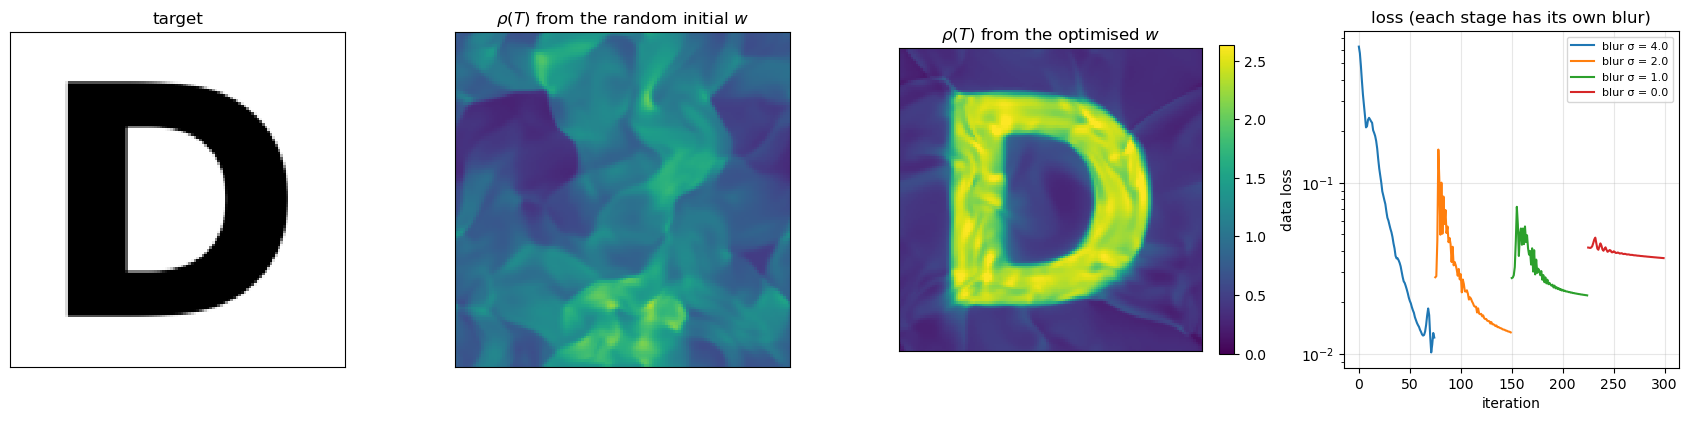

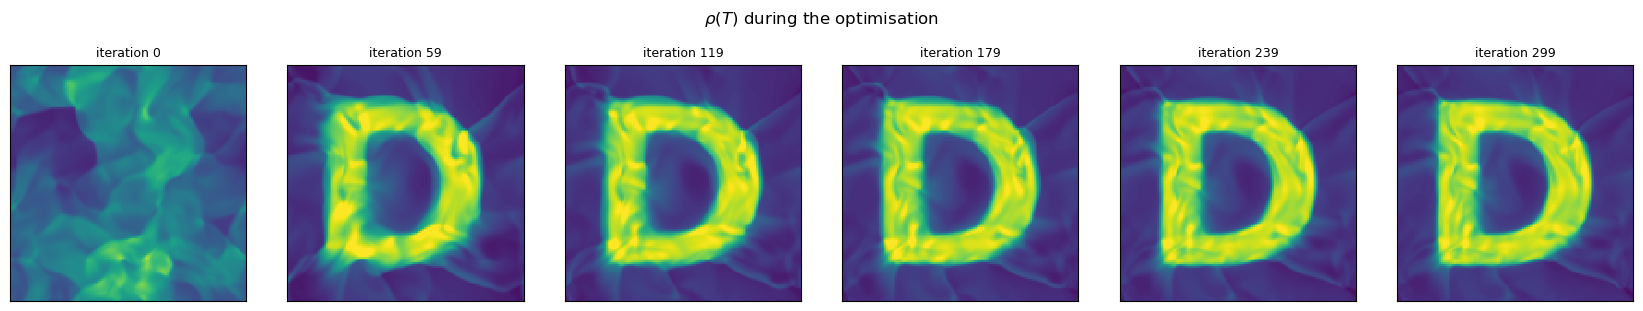

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
axes[0].imshow(ink.T, origin="lower", cmap="Greys"); axes[0].set_title("target")
vmax = np.percentile(rho_final, 99.5)
axes[1].imshow(np.asarray(rho_random).T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
axes[1].set_title(r"$\rho(T)$ from the random initial $w$")
im = axes[2].imshow(rho_final.T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
axes[2].set_title(r"$\rho(T)$ from the optimised $w$"); plt.colorbar(im, ax=axes[2], fraction=0.046)
for s in range(len(BLURS)):
    sel = history[:, 2] == s
    axes[3].semilogy(np.nonzero(sel)[0], history[sel, 1], label=f"blur σ = {blur_px[s]:.1f}")
axes[3].set_xlabel("iteration"); axes[3].set_ylabel("data loss"); axes[3].legend(fontsize=8); axes[3].grid(True, alpha=0.3)
axes[3].set_title("loss (each stage has its own blur)")
for ax in axes[:3]: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

fig, axes = plt.subplots(1, len(progress), figsize=(2.8 * len(progress), 3))
for ax, (it, r) in zip(axes, sorted(progress.items())):
    ax.imshow(r.T, origin="lower", cmap="viridis", vmin=0, vmax=vmax); ax.set_title(f"iteration {it}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(r"$\rho(T)$ during the optimisation", y=1.02); plt.tight_layout()

The loss jumps up each time the blur is reduced (the sharper target is harder to match), then keeps falling.

## 5. Watch it happen

The optimised IC is still just uniform gas with a turbulent-looking velocity field. Let's evolve it and watch the
letter assemble, and then keep going past $T$ to see the flow tear it apart again.

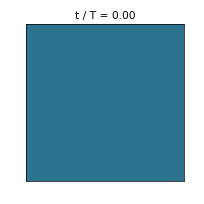

In [7]:
n_frames = 32
t_frames = np.linspace(0, 1.6 * T_END, n_frames + 1)
steps_per_frame = max(1, int(round(n_steps * (t_frames[1] / T_END))))
dts_frame = jnp.full((steps_per_frame,), t_frames[1] / steps_per_frame)
advance = jax.jit(lambda U: sim.evolve_with_dt_schedule(U, {}, dts_frame)[0])

def movie(w):
    # primitive states (rho, vx, vy, vz, p) at the frame times
    U = eq.get_conservatives_from_primitives(ic(w))
    out = [np.asarray(eq.get_primitives_from_conservatives(U)[..., 0])]
    for _ in range(n_frames):
        U = advance(U)
        out.append(np.asarray(eq.get_primitives_from_conservatives(U)[..., 0]))
    return np.array(out)

states = movie(w)
frames = states[:, 0]

from matplotlib import animation
from IPython.display import Image, display

fig, ax = plt.subplots(figsize=(3.2, 3.2), dpi=64)
im = ax.imshow(frames[0].T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
ttl = ax.set_title(""); ax.set_xticks([]); ax.set_yticks([])
def draw(i):
    im.set_data(frames[i].T); ttl.set_text(f"t / T = {t_frames[i] / T_END:.2f}")
    return im, ttl
anim = animation.FuncAnimation(fig, draw, frames=len(frames), interval=100)
gif_path = f"letter_{LETTER}.gif"
anim.save(gif_path, writer=animation.PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=gif_path))

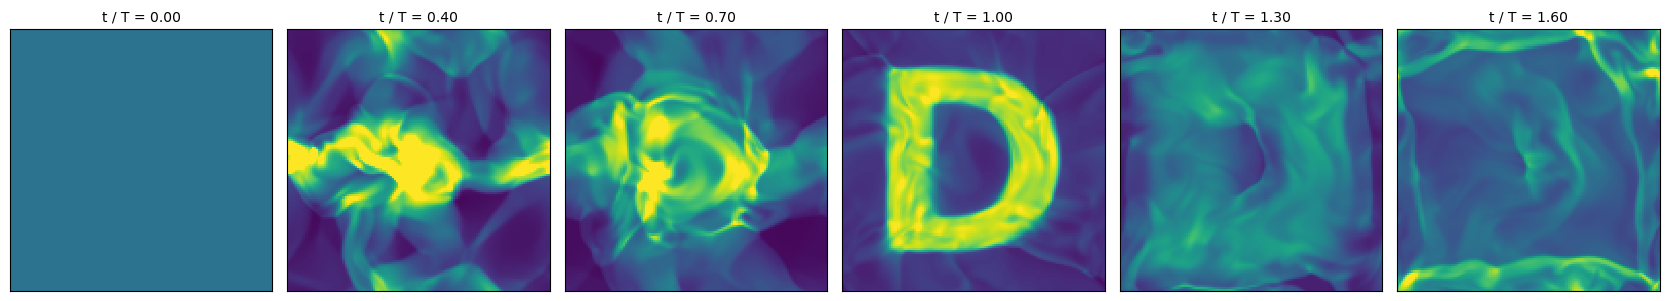

In [8]:
show = [0, 8, 14, 20, 26, 32]                     # t / T = 0, 0.4, 0.7, 1, 1.3, 1.6
fig, axes = plt.subplots(1, len(show), figsize=(2.8 * len(show), 3))
for ax, i in zip(axes, show):
    ax.imshow(frames[i].T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
    ax.set_title(f"t / T = {t_frames[i] / T_END:.2f}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

## 6. What did the optimizer do?

The gas starts uniform, so the letter has to be made by **moving** gas, and gas piles up where the flow converges,
$\nabla\cdot\mathbf v < 0$ (notebook 05). Is the optimised initial velocity field simply "the letter written in $-\nabla\cdot\mathbf v$"?

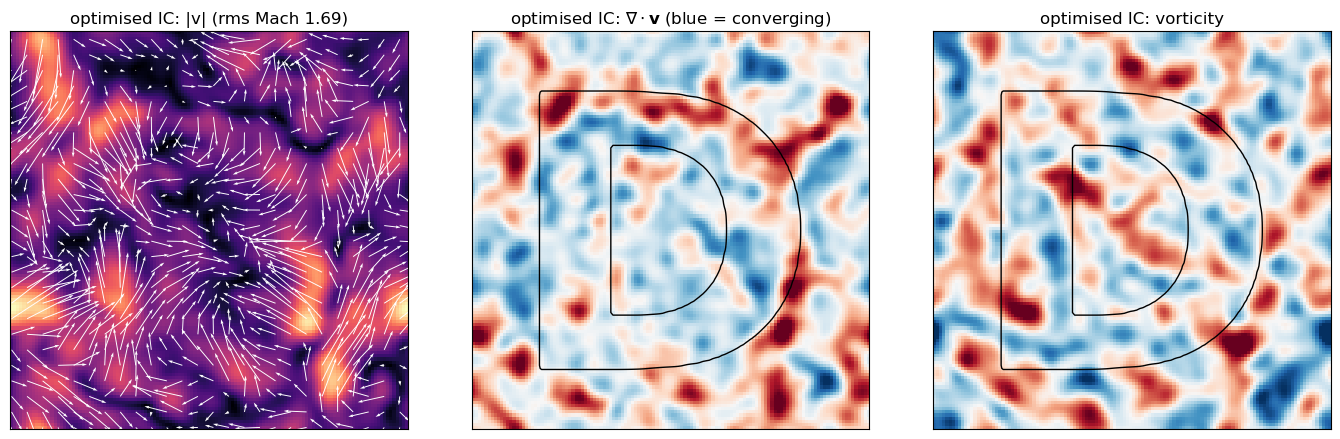

In [9]:
W_opt = np.asarray(ic(w))[..., 0]
div_opt, curl_opt = tu.div_curl_2d(W_opt[1], W_opt[2])
c = (np.arange(N) + 0.5) / N

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
speed = np.sqrt(W_opt[1] ** 2 + W_opt[2] ** 2)
axes[0].imshow(speed.T, origin="lower", cmap="magma", extent=[0, 1, 0, 1])
s = max(1, N // 24)
axes[0].quiver(c[::s], c[::s], W_opt[1][::s, ::s].T, W_opt[2][::s, ::s].T, color="w", scale=25)
axes[0].set_title(f"optimised IC: |v| (rms Mach {np.sqrt(np.mean(speed ** 2)):.2f})")
for ax, f, name in ((axes[1], div_opt, r"$\nabla\cdot\mathbf{v}$ (blue = converging)"), (axes[2], curl_opt, "vorticity")):
    lim = np.percentile(np.abs(f), 99)
    ax.imshow(f.T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim, extent=[0, 1, 0, 1])
    ax.contour(c, c, ink.T, levels=[0.5], colors="k", linewidths=1)
    ax.set_title("optimised IC: " + name)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

Not at all: at $t = 0$ the convergence pattern has no obvious relation to the letter. The gas that ends up in a
stroke travels $\sim v\,T \approx 0.3$–$0.4$ box widths to get there, comparable to the size of the letter itself, so
*where* the flow converges initially says little about where gas will be at $T$. Let's instead measure, at every
frame of the movie, how well the convergence $-\nabla\cdot\mathbf v(t)$ lines up with the letter, for the optimised and for
the original random initial condition.

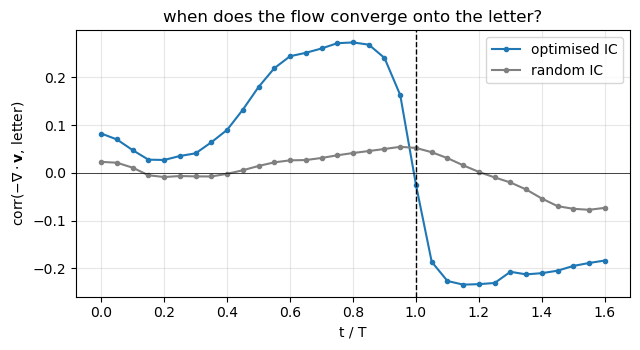

In [10]:
states_rand = movie(w_init)
smooth_ink = ndimage.gaussian_filter(ink, 2 * N / 128, mode="wrap")

def convergence_on_letter(states):
    out = []
    for W in states:
        div, _ = tu.div_curl_2d(W[1], W[2])
        out.append(np.corrcoef(-div.ravel(), smooth_ink.ravel())[0, 1])
    return np.array(out)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(t_frames / T_END, convergence_on_letter(states), "o-", ms=3, label="optimised IC")
ax.plot(t_frames / T_END, convergence_on_letter(states_rand), "o-", ms=3, color="gray", label="random IC")
ax.axvline(1, color="k", ls="--", lw=1); ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("t / T"); ax.set_ylabel(r"corr$(-\nabla\cdot\mathbf{v}$, letter$)$"); ax.legend(); ax.grid(True, alpha=0.3)
ax.set_title("when does the flow converge onto the letter?")
plt.tight_layout()

The letter is a **timed implosion**. At $t = 0$ the flow is barely aimed at the strokes. The convergence onto the
letter builds up as the gas travels, peaks around $t \approx 0.8\,T$, and changes sign almost exactly at $t = T$:
that is the moment of maximum compression, after which the strokes re-expand and the letter dissolves (as in the movie).
The random IC shows nothing of the sort. Engineering this by hand would mean inverting nonlinear, shock-forming
dynamics; the adjoint does it automatically, using both the compressive and the solenoidal parts of the flow.

Note also that the optimised flow is *faster* than a typical draw (rms Mach in the panel title) although $\langle w^2\rangle$
stayed ≈ 1: the optimiser moved power into the large-scale modes, where the $k^{-1}$ amplitude kernel turns unit
noise into the most velocity.

A few things worth knowing:

* **Non-uniqueness.** Many velocity fields can make the same letter; which one the optimiser finds depends on the
  starting $w$ (try another seed for `w_init`), and the prior only mildly prefers some over others.
* **Horizon.** Longer $T$ makes the problem more interesting (the IC looks even less like the target) but harder:
  gradients grow and decorrelate (notebook 05). Try `T_END = 0.5`; expect to need more iterations and a smaller learning rate.
* **Band limit.** `KCUT` controls the smallest eddies the optimiser may use. With `KCUT = 4` the strokes must be
  built by large-scale, smooth flows.
* **Resolution.** Thin strokes need several cells to be resolved by a shock-capturing scheme. $48^2$ works for a
  bold letter; $128^2$ or more gives crisp edges.

## Exercises

1. Change `LETTER` (try "S", "Ω" or a digit) or render a short word by widening the box.
2. Make the IC purely compressive (`solenoidal_fraction=0`) or purely solenoidal (`=1`). Which can still write the
   letter, and why? (Hint: notebook 05, section 2.)
3. Add **self-gravity**: `dh.physics.gravity.FFTSelfGravityForce(eq, G=..., subtract_mean=True)` in `forces=[...]` of
   `dh.hydro`. With gravity, small overdensities keep growing, so the flow can start weaker. How small can `MACH` be?
4. Replace the contrast loss by a loss on $\log\rho$ (structure in the voids then matters as much as in the strokes)
   and compare.
5. Go 3D: `logo_recon/` in this repository solves the same kind of problem at $128^3$ with the target imposed on a
   *projection* of the density, as in an astronomical image.

## Where to go from here

You have now seen the full chain, **finite-volume physics → differentiable programming → inverse problem**,
from a 20-line advection solver to an optimisation through hundreds of steps of a production hydro code.
The same pattern (parametrise the unknown initial or boundary conditions or physics with a well-conditioned
prior, differentiate the simulator, fit to data) underlies the research applications of diffhydro: reconstructing
supernova-remnant initial conditions from X-ray images, cosmological initial conditions from the Lyman-α forest, and
learning sub-grid closures for galaxy-formation physics.